In [1]:
# ==========================================================
# Crop Type Mapping using Multi-Season Sentinel-2 Data
# Study Area:
#   • Karnal (Haryana)
#   • Mansa (Punjab)
#
# Author: Anshuman Tripathi
#
# Workflow:
#   Sentinel-2
#        ↓
#   Feature Engineering
#        ↓
#   Vegetation Indices
#        ↓
#   Machine Learning
#        ↓
#   Accuracy Assessment
#        ↓
#   Publication Maps
# ==========================================================

In [2]:
# ==========================================================
# CELL 0 : INSTALL REQUIRED LIBRARIES
# Run only once
# ==========================================================

import sys

!{sys.executable} -m pip install -U \
numpy \
pandas \
matplotlib \
geopandas \
rasterio \
rioxarray \
xarray \
shapely \
scikit-learn \
scipy \
opencv-python \
jupyterlab

In [3]:
# ==========================================================
# CELL 1 : IMPORT LIBRARIES
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import os

# Numerical
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 8)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["font.size"] = 12

# Geospatial
import geopandas as gpd

import rasterio
from rasterio.plot import show
from rasterio.mask import mask

import rioxarray as rxr

from shapely.geometry import mapping

# Machine Learning
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import *

print("=" * 60)
print("Crop Type Mapping using Multi-season Sentinel-2")
print("=" * 60)
print("Libraries Imported Successfully.")

Crop Type Mapping using Multi-season Sentinel-2
Libraries Imported Successfully.


In [4]:
# ==========================================================
# CELL 2 : PROJECT CONFIGURATION
# ==========================================================

# -------------------------
# Study Area
# -------------------------
DISTRICT = "Karnal"
# Options:
# "Karnal"
# "Mansa"

# -------------------------
# Crop Season
# -------------------------
SEASON = "Kharif"
# Options:
# "Kharif"
# "Rabi"

# -------------------------
# Root Directory
# -------------------------
ROOT_DIR = Path(
    "/home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main"
)

DATA_DIR = ROOT_DIR / "data"
BOUNDARY_DIR = DATA_DIR / "boundary"
RASTER_DIR = DATA_DIR / "raster"

OUTPUT_DIR = ROOT_DIR / "outputs"
FIGURE_DIR = ROOT_DIR / "figure"
MODEL_DIR = ROOT_DIR / "models"

# Create folders if missing
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print(f"District : {DISTRICT}")
print(f"Season   : {SEASON}")

District : Karnal
Season   : Kharif


In [5]:
# ==========================================================
# CELL 3 : FILE PATHS
# ==========================================================

boundary_file = BOUNDARY_DIR / f"{DISTRICT}_Boundary.shp"

raster_file = RASTER_DIR / f"{DISTRICT}_{SEASON}_SelectedBands.tif"

print("Boundary File")
print(boundary_file)

print("\nRaster File")
print(raster_file)

print("\nBoundary Exists :", boundary_file.exists())
print("Raster Exists   :", raster_file.exists())

Boundary File
/home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/data/boundary/Karnal_Boundary.shp

Raster File
/home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/data/raster/Karnal_Kharif_SelectedBands.tif

Boundary Exists : True
Raster Exists   : True


In [6]:
# ==========================================================
# CELL 4 : LOAD AOI SHAPEFILE
# ==========================================================

# Read district boundary
aoi = gpd.read_file(boundary_file)

# Display basic information
print("=" * 60)
print("Administrative Boundary Loaded")
print("=" * 60)

print(f"District : {DISTRICT}")
print(f"Features : {len(aoi)}")
print(f"CRS      : {aoi.crs}")

display(aoi.head())

Administrative Boundary Loaded
District : Karnal
Features : 1
CRS      : EPSG:4326


,Shape_Leng,STATUS,ADM1_CODE,ADM0_NAME,STR2_YEAR,ADM2_NAME,ADM0_CODE,EXP2_YEAR,Shape_Area,ADM2_CODE,DISP_AREA,ADM1_NAME,geometry
0,2.773671,Member State,1492,India,1990,Karnal,115,3000,0.240933,17660,NO,Haryana,"POLYGON ((76.48194 29.51891, 76.49 29.53094, 7..."


In [7]:
# ==========================================================
# SAVE UTILITIES (Run once)
# ==========================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

# ----------------------------------------------------------
# Output folders
# ----------------------------------------------------------

OUTPUT_DIR = ROOT_DIR / "outputs"

FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
RASTER_DIR = OUTPUT_DIR / "rasters"

for folder in [
    OUTPUT_DIR,
    FIGURE_DIR,
    TABLE_DIR,
    RASTER_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------
# Save Current Figure
# ----------------------------------------------------------

def save_figure(
    filename,
    dpi=600,
    transparent=False
):
    """
    Save current matplotlib figure.
    """

    filepath = FIGURE_DIR / f"{filename}.png"

    plt.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight",
        transparent=transparent
    )

    print(f"✓ Figure saved -> {filepath}")

# ----------------------------------------------------------
# Save DataFrame
# ----------------------------------------------------------

def save_csv(df, filename):
    """
    Save dataframe as CSV.
    """

    filepath = TABLE_DIR / f"{filename}.csv"

    df.to_csv(
        filepath,
        index=False
    )

    print(f"✓ CSV saved -> {filepath}")

# ==========================================================
# SAVE RASTER
# ==========================================================

def save_raster(image, meta, filename):

    import rasterio
    import numpy as np

    filepath = RASTER_DIR / f"{filename}.tif"

    meta = meta.copy()

    if image.ndim == 2:

        meta.update(count=1)

        with rasterio.open(
            filepath,
            "w",
            **meta
        ) as dst:

            dst.write(
                image.astype(np.float32),
                1
            )

    elif image.ndim == 3:

        meta.update(count=image.shape[0])

        with rasterio.open(
            filepath,
            "w",
            **meta
        ) as dst:

            dst.write(
                image.astype(np.float32)
            )

    else:

        raise ValueError(
            f"Unsupported image shape: {image.shape}"
        )

    print(f"✓ Raster saved → {filepath}")
print("="*60)
print("Saving utilities loaded successfully.")
print("="*60)

Saving utilities loaded successfully.


✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/District_Boundary.png


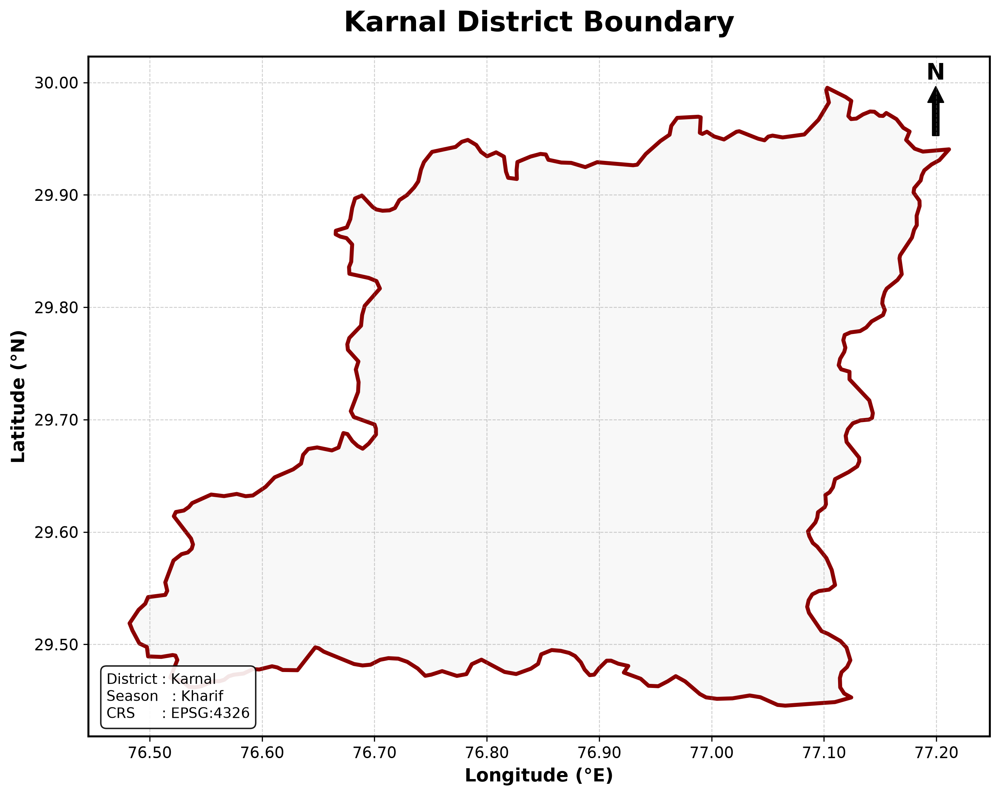

In [8]:
# ==========================================================
# CELL 5 : PUBLICATION QUALITY AOI MAP
# ==========================================================

import matplotlib.ticker as mticker
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(10, 10))

# ==========================================================
# DISTRICT BOUNDARY
# ==========================================================

aoi.plot(
    ax=ax,
    facecolor="#F8F8F8",
    edgecolor="darkred",
    linewidth=2.8
)

# ==========================================================
# TITLE
# ==========================================================

ax.set_title(
    f"{DISTRICT} District Boundary",
    fontsize=20,
    fontweight="bold",
    pad=18
)

# ==========================================================
# AXIS LABELS
# ==========================================================

ax.set_xlabel(
    "Longitude (°E)",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Latitude (°N)",
    fontsize=13,
    fontweight="bold"
)

# ==========================================================
# GRID
# ==========================================================

ax.grid(
    linestyle="--",
    linewidth=0.6,
    alpha=0.4,
    color="gray"
)

# ==========================================================
# TICK FORMAT
# ==========================================================

ax.xaxis.set_major_formatter(
    mticker.FormatStrFormatter("%.2f")
)

ax.yaxis.set_major_formatter(
    mticker.FormatStrFormatter("%.2f")
)

ax.tick_params(
    labelsize=11
)

# ==========================================================
# KEEP TRUE MAP SCALE
# ==========================================================

ax.set_aspect("equal")

# ==========================================================
# NORTH ARROW
# ==========================================================

arrow = FancyArrowPatch(
    (0.94, 0.88),
    (0.94, 0.96),
    transform=ax.transAxes,
    arrowstyle='simple',
    mutation_scale=22,
    color='black'
)

ax.add_patch(arrow)

ax.text(
    0.94,
    0.975,
    "N",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

# ==========================================================
# INFORMATION BOX
# ==========================================================

info = (
    f"District : {DISTRICT}\n"
    f"Season   : {SEASON}\n"
    f"CRS      : {aoi.crs.to_string()}"
)

ax.text(
    0.02,
    0.02,
    info,
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="black",
        alpha=0.90,
        boxstyle="round,pad=0.4"
    )
)

# ==========================================================
# BORDER
# ==========================================================

for spine in ax.spines.values():
    spine.set_linewidth(1.4)

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("District_Boundary")

# ==========================================================
# DISPLAY
# ==========================================================

plt.tight_layout()
plt.show()

In [9]:
# ==========================================================
# CELL 6 : LOAD MULTI-BAND RASTER
# ==========================================================

src = rasterio.open(raster_file)

print("=" * 60)
print("Sentinel-2 Raster Loaded")
print("=" * 60)

print("Raster Name :", raster_file.name)
print("Bands       :", src.count)
print("Width       :", src.width)
print("Height      :", src.height)
print("CRS         :", src.crs)
print("Resolution  :", src.res)
print("Bounds      :", src.bounds)

Sentinel-2 Raster Loaded
Raster Name : Karnal_Kharif_SelectedBands.tif
Bands       : 6
Width       : 8118
Height      : 6122
CRS         : EPSG:4326
Resolution  : (8.983152841195215e-05, 8.983152841195215e-05)
Bounds      : BoundingBox(left=76.48193446923717, bottom=29.44560720356856, right=77.2111868168854, top=29.99555582050653)


In [10]:
# ==========================================================
# CELL 7 : RASTER METADATA
# ==========================================================

metadata = {

    "Driver": src.driver,

    "Width": src.width,

    "Height": src.height,

    "Bands": src.count,

    "CRS": src.crs,

    "Resolution": src.res,

    "Data Type": src.dtypes[0],

    "NoData": src.nodata,

}

metadata_df = pd.DataFrame(
    metadata.items(),
    columns=["Property","Value"]
)

display(metadata_df)

,Property,Value
0,Driver,GTiff
1,Width,8118
2,Height,6122
3,Bands,6
4,CRS,"(proj, datum, no_defs)"
5,Resolution,"(8.983152841195215e-05, 8.983152841195215e-05)"
6,Data Type,float64
7,NoData,None


In [11]:
# ==========================================================
# CELL 8 : BAND INFORMATION
# ==========================================================

band_names = [

    "Blue (B2)",

    "Green (B3)",

    "Red (B4)",

    "NIR (B8)",

    "SWIR-1 (B11)",

    "SWIR-2 (B12)"

]

band_df = pd.DataFrame({

    "Band Number": range(1,7),

    "Sentinel Band": band_names

})

display(band_df)

,Band Number,Sentinel Band
0,1,Blue (B2)
1,2,Green (B3)
2,3,Red (B4)
3,4,NIR (B8)
4,5,SWIR-1 (B11)
5,6,SWIR-2 (B12)


In [12]:
# ==========================================================
# CELL 9 : READ RASTER BANDS
# ==========================================================

blue = src.read(1).astype(np.float32)

green = src.read(2).astype(np.float32)

red = src.read(3).astype(np.float32)

nir = src.read(4).astype(np.float32)

swir1 = src.read(5).astype(np.float32)

swir2 = src.read(6).astype(np.float32)

print("Bands Loaded Successfully")

Bands Loaded Successfully


In [13]:
# ==========================================================
# CELL 10 : VERIFY BAND SHAPES
# ==========================================================

print("Blue   :", blue.shape)

print("Green  :", green.shape)

print("Red    :", red.shape)

print("NIR    :", nir.shape)

print("SWIR1  :", swir1.shape)

print("SWIR2  :", swir2.shape)

Blue   : (6122, 8118)
Green  : (6122, 8118)
Red    : (6122, 8118)
NIR    : (6122, 8118)
SWIR1  : (6122, 8118)
SWIR2  : (6122, 8118)


In [2]:
# ==========================================================
# CELL 11 : TRUE COLOR (RGB) COMPOSITE
# Sentinel-2 Bands:
#   Red   = B4
#   Green = B3
#   Blue  = B2
# ==========================================================

# Stretch values to improve visualization
rgb = np.dstack((red, green, blue))

rgb = np.clip(rgb / 3000, 0, 1)

fig, ax = plt.subplots(figsize=(10,10))

ax.imshow(rgb)

ax.set_title(
    f"{DISTRICT} - {SEASON} (True Color Composite)",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Column (Pixels)")
ax.set_ylabel("Row (Pixels)")

# ----------------------------------------------------------
# North Arrow
# ----------------------------------------------------------

ax.annotate(
    'N',
    xy=(0.97, 0.96),
    xytext=(0.97, 0.88),
    arrowprops=dict(
        facecolor='black',
        width=4,
        headwidth=12
    ),
    ha='center',
    va='center',
    fontsize=16,
    fontweight='bold',
    xycoords=ax.transAxes
)

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("Karnal-Kharif (TRUE COLOR COMPOSITE)")


plt.tight_layout()

plt.show()


NameError: name 'np' is not defined

In [1]:
# ==========================================================
# CELL 12 : FALSE COLOR COMPOSITE
# NIR - RED - GREEN
# ==========================================================

fcc = np.dstack((nir, red, green))

fcc = np.clip(fcc / 3000, 0, 1)

fig, ax = plt.subplots(figsize=(10,10))

ax.imshow(fcc)

ax.set_title(
    f"{DISTRICT} - {SEASON} (False Color Composite)",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Column (Pixels)")
ax.set_ylabel("Row (Pixels)")

# ----------------------------------------------------------
# North Arrow
# ----------------------------------------------------------

ax.annotate(
    'N',
    xy=(0.97, 0.96),
    xytext=(0.97, 0.88),
    arrowprops=dict(
        facecolor='black',
        width=4,
        headwidth=12
    ),
    ha='center',
    va='center',
    fontsize=16,
    fontweight='bold',
    xycoords=ax.transAxes
)

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("Karnal-Kharif (False COLOR COMPOSITE)")

plt.tight_layout()

plt.show()

NameError: name 'np' is not defined

In [16]:
# ==========================================================
# CELL 13 : BAND STATISTICS
# ==========================================================

bands = {
    "Blue (B2)" : blue,
    "Green (B3)": green,
    "Red (B4)"  : red,
    "NIR (B8)"  : nir,
    "SWIR1 (B11)": swir1,
    "SWIR2 (B12)": swir2
}

stats = []

for name, band in bands.items():

    valid = band[band > 0]

    stats.append({

        "Band": name,

        "Minimum": np.min(valid),

        "Maximum": np.max(valid),

        "Mean": np.mean(valid),

        "Median": np.median(valid),

        "Std Dev": np.std(valid)

    })

stats_df = pd.DataFrame(stats)

display(stats_df.round(2))

,Band,Minimum,Maximum,Mean,Median,Std Dev
0,Blue (B2),0.5,11000.0,427.640015,316.0,384.679993
1,Green (B3),1.0,10144.0,771.190002,666.0,385.809998
2,Red (B4),3.0,9272.0,601.880005,439.0,459.750000
3,NIR (B8),135.0,7848.0,3693.120117,3796.0,617.200012
4,SWIR1 (B11),282.0,9395.0,1953.819946,1841.0,406.209991
5,SWIR2 (B12),180.0,11952.5,1119.400024,950.5,463.989990


In [3]:
# ==========================================================
# CELL 14 : BOXPLOT OF SPECTRAL BANDS
# ==========================================================

data = []
band_labels = []

for name, band in bands.items():

    valid = band[band > 0]

    # Random sample to reduce memory usage
    sample = np.random.choice(
        valid,
        size=min(10000, len(valid)),
        replace=False
    )

    data.append(sample)
    band_labels.append(name)

fig, ax = plt.subplots(figsize=(12, 6))

ax.boxplot(
    data,
    tick_labels=band_labels,      # <-- Updated for Matplotlib 3.9+
    showfliers=False,
    patch_artist=True
)

ax.set_title(
    "Spectral Distribution of Sentinel-2 Bands",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel("Reflectance")
plt.xticks(rotation=20)

plt.grid(axis="y", linestyle="--", alpha=0.4)

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("Karnal-Kharif (Spectral Distribution of Sentinal-2 Bands)")

plt.tight_layout()

plt.show()

NameError: name 'bands' is not defined

In [18]:
print(blue.shape)
print(green.shape)
print(red.shape)
print(nir.shape)
print(swir1.shape)
print(swir2.shape)

(6122, 8118)
(6122, 8118)
(6122, 8118)
(6122, 8118)
(6122, 8118)
(6122, 8118)


✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/Karnal-Kharif (Histogram of Sentinal-2 Spectral Bands).png


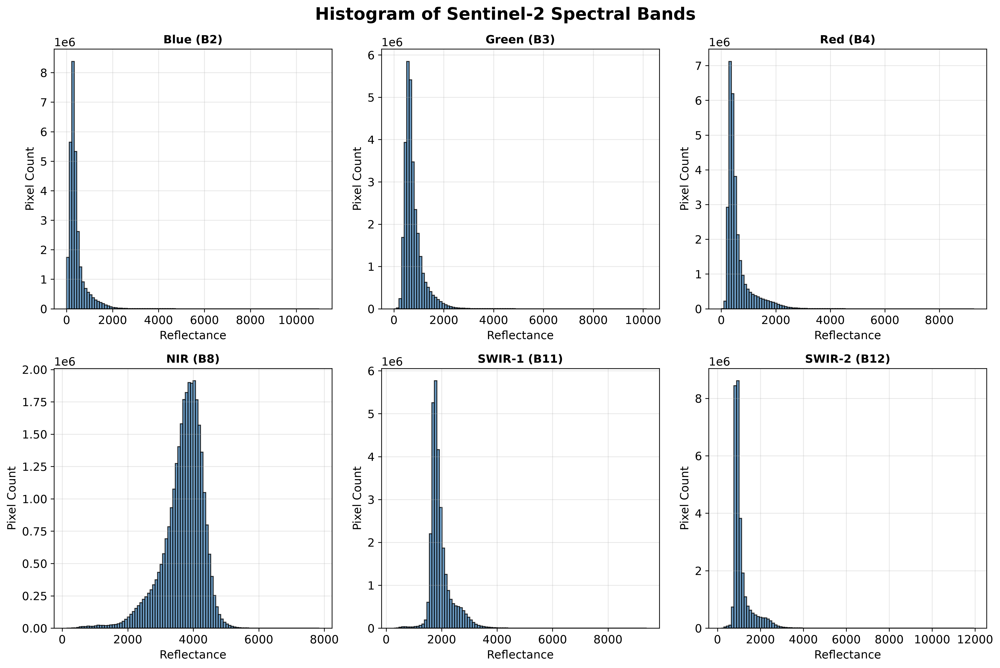

In [19]:
# ==========================================================
# CELL 15 : HISTOGRAM OF SPECTRAL BANDS
# ==========================================================

bands = {
    "Blue (B2)": blue,
    "Green (B3)": green,
    "Red (B4)": red,
    "NIR (B8)": nir,
    "SWIR-1 (B11)": swir1,
    "SWIR-2 (B12)": swir2
}

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.ravel()

for ax, (name, band) in zip(axes, bands.items()):

    valid = band[band > 0]

    ax.hist(
        valid,
        bins=100,
        color="steelblue",
        edgecolor="black",
        alpha=0.8
    )

    ax.set_title(name, fontsize=12, fontweight="bold")
    ax.set_xlabel("Reflectance")
    ax.set_ylabel("Pixel Count")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Histogram of Sentinel-2 Spectral Bands",
    fontsize=18,
    fontweight="bold"
)

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("Karnal-Kharif (Histogram of Sentinal-2 Spectral Bands)")

plt.tight_layout()

plt.show()

In [20]:
# ==========================================================
# DIAGNOSTIC : CHECK CRS AND BOUNDS
# ==========================================================

print("="*60)
print("Raster CRS")
print(src.crs)

print("\nRaster Bounds")
print(src.bounds)

print("\n" + "="*60)
print("AOI CRS")
print(aoi.crs)

print("\nAOI Total Bounds")
print(aoi.total_bounds)

Raster CRS
EPSG:4326

Raster Bounds
BoundingBox(left=76.48193446923717, bottom=29.44560720356856, right=77.2111868168854, top=29.99555582050653)

AOI CRS
EPSG:4326

AOI Total Bounds
[76.4819394  29.44565149 77.21112733 29.99548987]


In [21]:
# ==========================================================
# REPROJECT AOI TO MATCH RASTER CRS
# ==========================================================

aoi = aoi.to_crs(src.crs)

print("AOI CRS after reprojection:")
print(aoi.crs)

AOI CRS after reprojection:
GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]


In [22]:
print(src.crs)
print(aoi.crs)

EPSG:4326
GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]


✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/Karnal-Kharif (Verify Raster).png


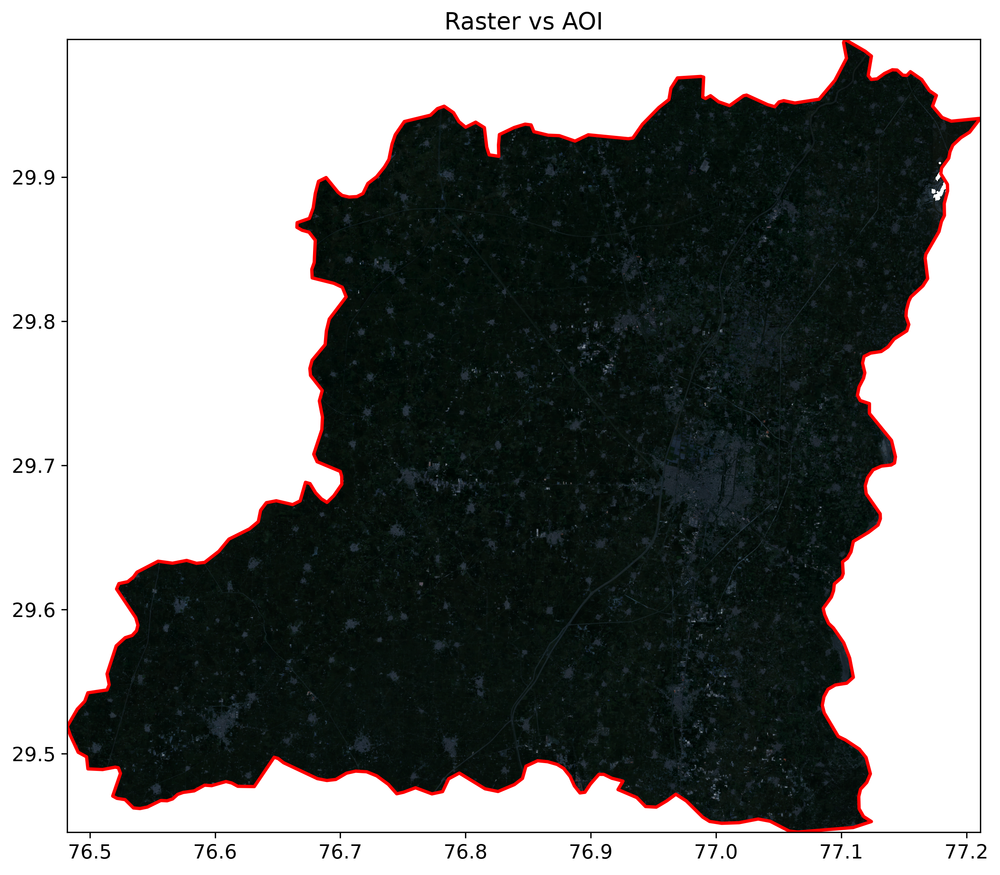

In [23]:
# ==========================================================
# CELL : VERIFY RASTER LOCATION
# ==========================================================

fig, ax = plt.subplots(figsize=(10,10))

# Plot raster extent
show(src, ax=ax)

# Plot AOI
aoi.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2
)

ax.set_title("Raster vs AOI")

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("Karnal-Kharif (Verify Raster)")

plt.show()

In [24]:
# ==========================================================
# CELL 16 : CLIP RASTER TO AOI
# ==========================================================

# Convert geometry into Rasterio format
geometry = [mapping(aoi.geometry.iloc[0])]

# Clip raster
clipped_image, clipped_transform = mask(
    src,
    geometry,
    crop=True
)

print("Clipped Raster Shape:", clipped_image.shape)

Clipped Raster Shape: (6, 6122, 8118)


✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/Karnal-Kharif (true COLOR COMPOSITE rgb cliped).png


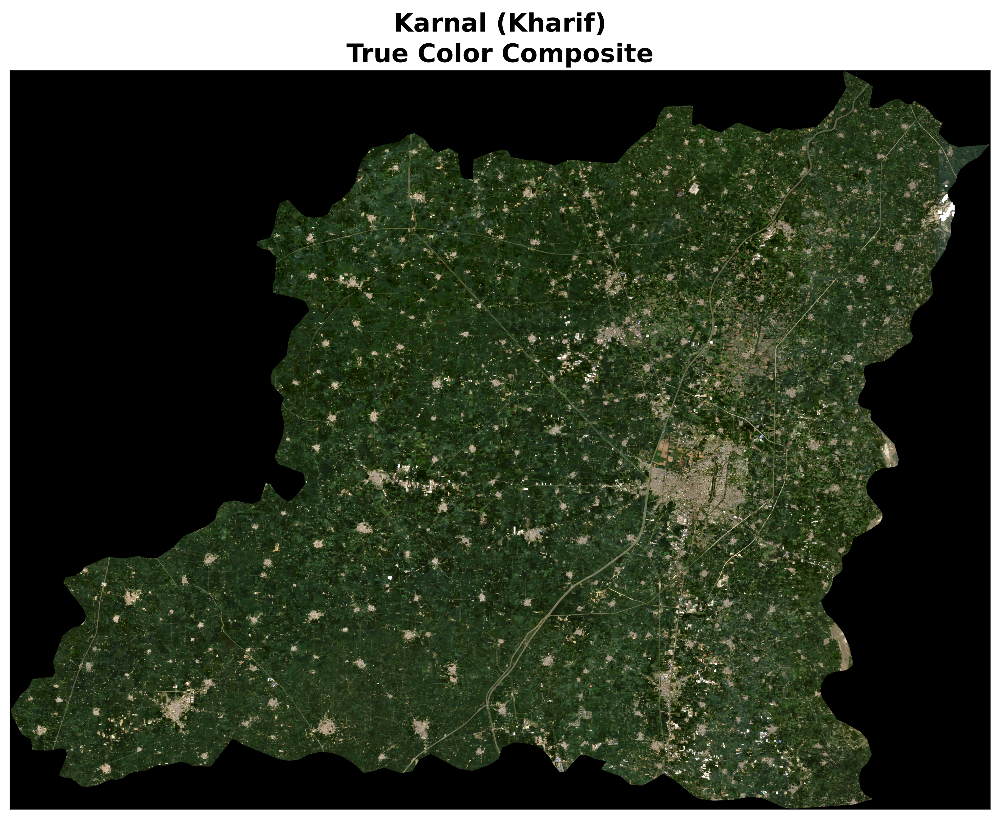

In [25]:
# ==========================================================
# CELL 17 : RGB COMPOSITE (CLIPPED)
# ==========================================================

# Extract clipped bands
blue_clip = clipped_image[0].astype(np.float32)
green_clip = clipped_image[1].astype(np.float32)
red_clip = clipped_image[2].astype(np.float32)

# Stack RGB
rgb_clip = np.dstack((red_clip, green_clip, blue_clip))

# Stretch
rgb_clip = np.clip(rgb_clip / 3000, 0, 1)

fig, ax = plt.subplots(figsize=(10, 10))

ax.imshow(rgb_clip)

ax.set_title(
    f"{DISTRICT} ({SEASON})\nTrue Color Composite",
    fontsize=18,
    fontweight="bold"
)

ax.set_xticks([])
ax.set_yticks([])

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("Karnal-Kharif (true COLOR COMPOSITE rgb cliped)")

plt.tight_layout()

plt.show()

✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/Karnal-(Kharif) (False COLOR COMPOSITE).png


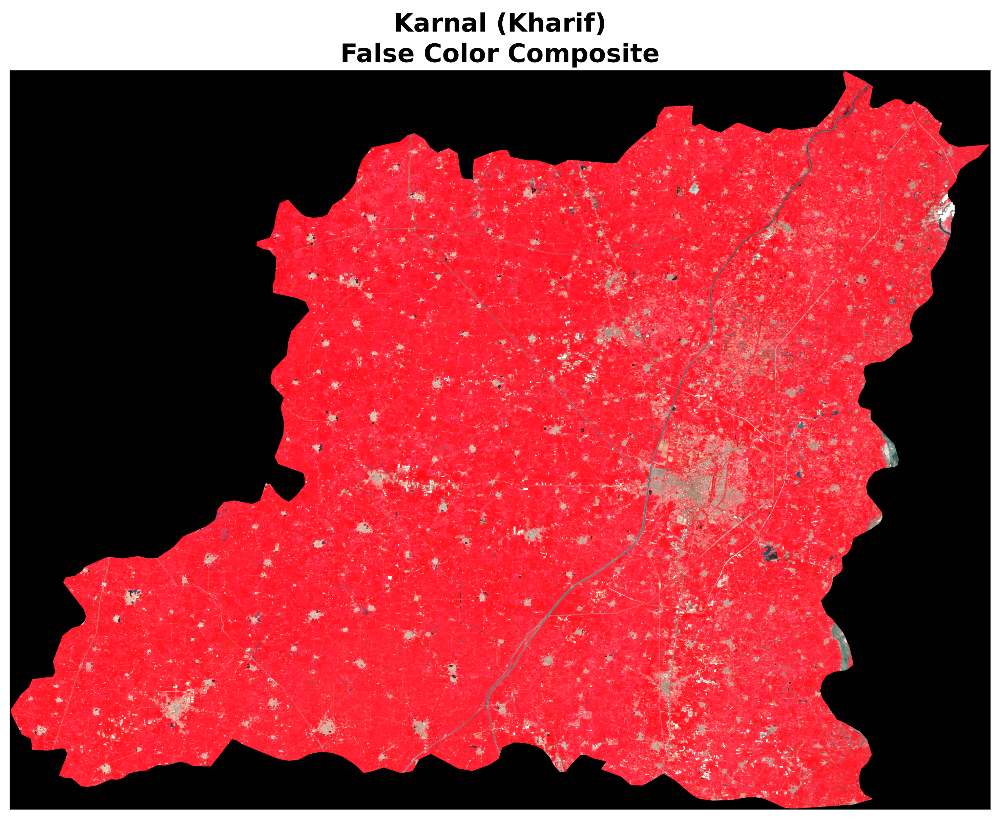

In [26]:
# ==========================================================
# CELL 18 : FALSE COLOR COMPOSITE
# ==========================================================

nir_clip = clipped_image[3].astype(np.float32)

fcc = np.dstack((nir_clip, red_clip, green_clip))

fcc = np.clip(fcc / 3000, 0, 1)

fig, ax = plt.subplots(figsize=(10,10))

ax.imshow(fcc)

ax.set_title(
    f"{DISTRICT} ({SEASON})\nFalse Color Composite",
    fontsize=18,
    fontweight="bold"
)

ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "Karnal(Kharif) False Color Composite.png",
    dpi=600,
    bbox_inches="tight"
)
# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure("Karnal-(Kharif) (False COLOR COMPOSITE)")

plt.show()

In [27]:
# ==========================================================
# CELL 19 : NDVI CALCULATION & EXPORT
# ==========================================================

import numpy as np
import pandas as pd

# ----------------------------------------------------------
# NDVI Formula
# NDVI = (NIR - RED) / (NIR + RED)
# ----------------------------------------------------------

np.seterr(divide="ignore", invalid="ignore")

ndvi = (nir_clip - red_clip) / (nir_clip + red_clip)

# Replace infinite values
ndvi = np.where(np.isfinite(ndvi), ndvi, np.nan)

print("="*60)
print("NDVI CALCULATED SUCCESSFULLY")
print("="*60)

print(f"Minimum NDVI : {np.nanmin(ndvi):.4f}")
print(f"Maximum NDVI : {np.nanmax(ndvi):.4f}")
print(f"Mean NDVI    : {np.nanmean(ndvi):.4f}")
print(f"Median NDVI  : {np.nanmedian(ndvi):.4f}")
print(f"Std Dev      : {np.nanstd(ndvi):.4f}")

# ==========================================================
# SAVE NDVI RASTER
# ==========================================================

ndvi_meta = src.meta.copy()

ndvi_meta.update({

    "driver": "GTiff",
    "height": ndvi.shape[0],
    "width": ndvi.shape[1],
    "count": 1,
    "dtype": "float32",
    "transform": clipped_transform

})

save_raster(

    ndvi.astype(np.float32),

    ndvi_meta,

    f"{DISTRICT}_{SEASON}_NDVI"

)

# ==========================================================
# NDVI STATISTICS
# ==========================================================

valid = ndvi[np.isfinite(ndvi)]

ndvi_stats = pd.DataFrame({

    "Statistic":[
        "Minimum",
        "Maximum",
        "Mean",
        "Median",
        "Standard Deviation"
    ],

    "Value":[
        np.min(valid),
        np.max(valid),
        np.mean(valid),
        np.median(valid),
        np.std(valid)
    ]

})

display(ndvi_stats.round(4))

# ==========================================================
# SAVE CSV
# ==========================================================

save_csv(

    ndvi_stats,

    f"{DISTRICT}_{SEASON}_NDVI_Statistics"

)

print("\n✓ NDVI Raster Saved")
print("✓ NDVI Statistics Saved")

NDVI CALCULATED SUCCESSFULLY
Minimum NDVI : -0.5014
Maximum NDVI : 1.0000
Mean NDVI    : 0.7183
Median NDVI  : 0.7915
Std Dev      : 0.2013
✓ Raster saved → /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/rasters/Karnal_Kharif_NDVI.tif


,Statistic,Value
0,Minimum,-0.5014
1,Maximum,1.0000
2,Mean,0.7183
3,Median,0.7915
4,Standard Deviation,0.2013


✓ CSV saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/tables/Karnal_Kharif_NDVI_Statistics.csv

✓ NDVI Raster Saved
✓ NDVI Statistics Saved


In [28]:
import inspect

print(inspect.getsource(save_raster))

def save_raster(image, meta, filename):

    import rasterio
    import numpy as np

    filepath = RASTER_DIR / f"{filename}.tif"

    meta = meta.copy()

    if image.ndim == 2:

        meta.update(count=1)

        with rasterio.open(
            filepath,
            "w",
            **meta
        ) as dst:

            dst.write(
                image.astype(np.float32),
                1
            )

    elif image.ndim == 3:

        meta.update(count=image.shape[0])

        with rasterio.open(
            filepath,
            "w",
            **meta
        ) as dst:

            dst.write(
                image.astype(np.float32)
            )

    else:

        raise ValueError(
            f"Unsupported image shape: {image.shape}"
        )

    print(f"✓ Raster saved → {filepath}")



✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/Karnal-Kharif NDVI Map.png


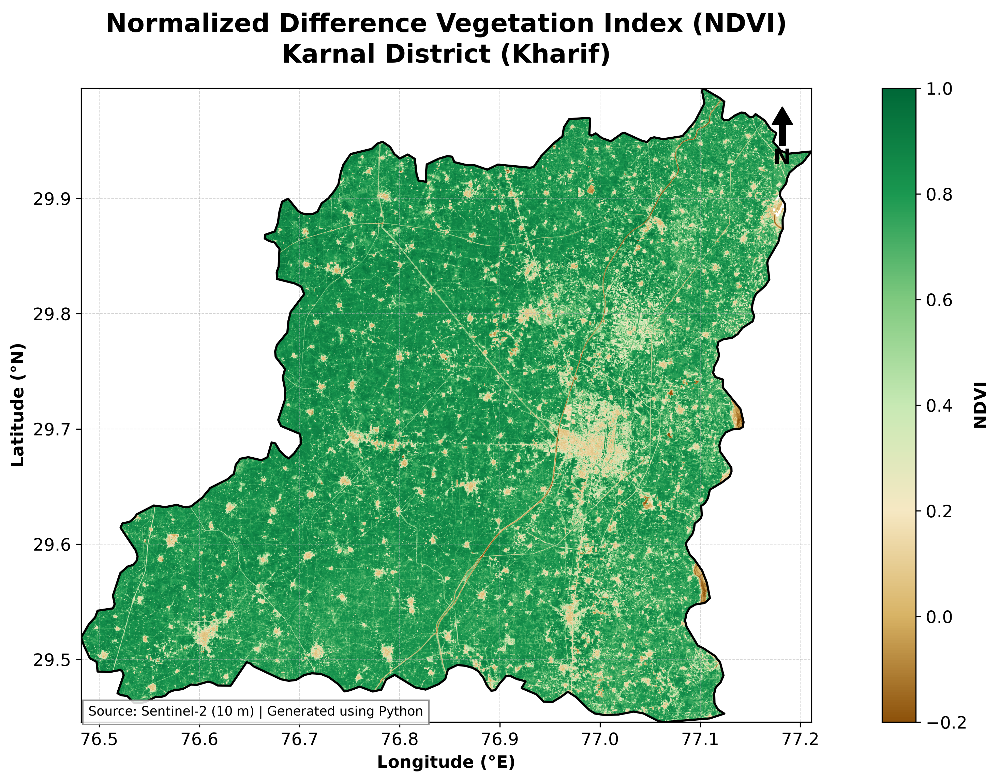

In [29]:
# ==========================================================
# CELL 20 : PUBLICATION QUALITY NDVI MAP
# ==========================================================

from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ----------------------------------------------------------
# Scientific NDVI Colormap
# ----------------------------------------------------------

ndvi_cmap = LinearSegmentedColormap.from_list(

    "NDVI",

    [

        "#8c510a",   # Bare soil
        "#d8b365",
        "#f6e8c3",
        "#c7e9b4",
        "#7fc97f",
        "#1a9850",
        "#006837"

    ]

)

# ----------------------------------------------------------
# Create Figure
# ----------------------------------------------------------

fig, ax = plt.subplots(

    figsize=(10,10)

)

# ----------------------------------------------------------
# Plot NDVI
# ----------------------------------------------------------

img = ax.imshow(

    ndvi,

    cmap=ndvi_cmap,

    vmin=-0.2,

    vmax=1,

    extent=(
        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top
    )

)

# ----------------------------------------------------------
# AOI Boundary
# ----------------------------------------------------------

aoi.boundary.plot(

    ax=ax,

    color="black",

    linewidth=1.5

)

# ----------------------------------------------------------
# Grid
# ----------------------------------------------------------

ax.grid(

    linestyle="--",

    linewidth=0.5,

    alpha=0.5

)

# ----------------------------------------------------------
# Labels
# ----------------------------------------------------------

ax.set_xlabel(

    "Longitude (°E)",

    fontsize=12,

    fontweight="bold"

)

ax.set_ylabel(

    "Latitude (°N)",

    fontsize=12,

    fontweight="bold"

)

# ----------------------------------------------------------
# Title
# ----------------------------------------------------------

ax.set_title(

    f"Normalized Difference Vegetation Index (NDVI)\n"
    f"{DISTRICT} District ({SEASON})",

    fontsize=18,

    fontweight="bold",

    pad=18

)

# ----------------------------------------------------------
# North Arrow
# ----------------------------------------------------------

ax.annotate(

    "N",

    xy=(0.96,0.97),

    xytext=(0.96,0.88),

    arrowprops=dict(

        facecolor="black",

        width=4,

        headwidth=14

    ),

    ha="center",

    fontsize=15,

    fontweight="bold",

    xycoords=ax.transAxes

)

# ----------------------------------------------------------
# Colorbar
# ----------------------------------------------------------

divider = make_axes_locatable(ax)

cax = divider.append_axes(

    "right",

    size="4%",

    pad=0.15

)

cb = plt.colorbar(

    img,

    cax=cax

)

cb.set_label(

    "NDVI",

    fontsize=12,

    fontweight="bold"

)

# ----------------------------------------------------------
# Footer
# ----------------------------------------------------------

ax.text(

    0.01,

    0.01,

    "Source: Sentinel-2 (10 m) | Generated using Python",

    fontsize=9,

    transform=ax.transAxes,

    bbox=dict(

        facecolor="white",

        alpha=0.85,

        edgecolor="gray"

    )

)

plt.tight_layout()



# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure(

    f"{DISTRICT}-{SEASON} NDVI Map"

)

plt.show()


✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/NDVI_Histogram.png


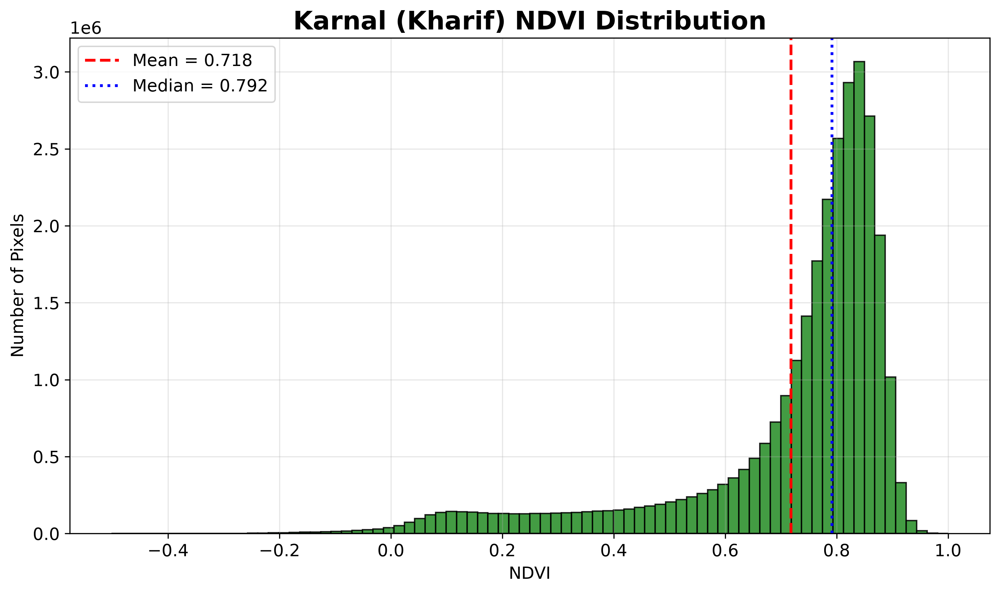

In [30]:
# ==========================================================
# CELL 21 : NDVI HISTOGRAM
# ==========================================================

valid_ndvi = ndvi[np.isfinite(ndvi)]

fig, ax = plt.subplots(figsize=(10,6))

ax.hist(
    valid_ndvi,
    bins=80,
    color="forestgreen",
    edgecolor="black",
    alpha=0.85
)

ax.axvline(
    np.mean(valid_ndvi),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {np.mean(valid_ndvi):.3f}"
)

ax.axvline(
    np.median(valid_ndvi),
    color="blue",
    linestyle=":",
    linewidth=2,
    label=f"Median = {np.median(valid_ndvi):.3f}"
)

ax.set_title(
    f"{DISTRICT} ({SEASON}) NDVI Distribution",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("NDVI")
ax.set_ylabel("Number of Pixels")

ax.grid(alpha=0.3)

ax.legend()

plt.tight_layout()

save_figure("NDVI_Histogram")

plt.show()

In [31]:
# ==========================================================
# CELL 22 : NDVI CLASSIFICATION
# ==========================================================

ndvi_class = np.full(ndvi.shape, np.nan)

ndvi_class[(ndvi < 0)] = 0
ndvi_class[(ndvi >= 0) & (ndvi < 0.2)] = 1
ndvi_class[(ndvi >= 0.2) & (ndvi < 0.5)] = 2
ndvi_class[(ndvi >= 0.5)] = 3

classes = {

0:"Water/Built-up",

1:"Bare Soil",

2:"Moderate Vegetation",

3:"Dense Vegetation"

}

print(classes)

{0: 'Water/Built-up', 1: 'Bare Soil', 2: 'Moderate Vegetation', 3: 'Dense Vegetation'}


✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/NDVI_Classes.png


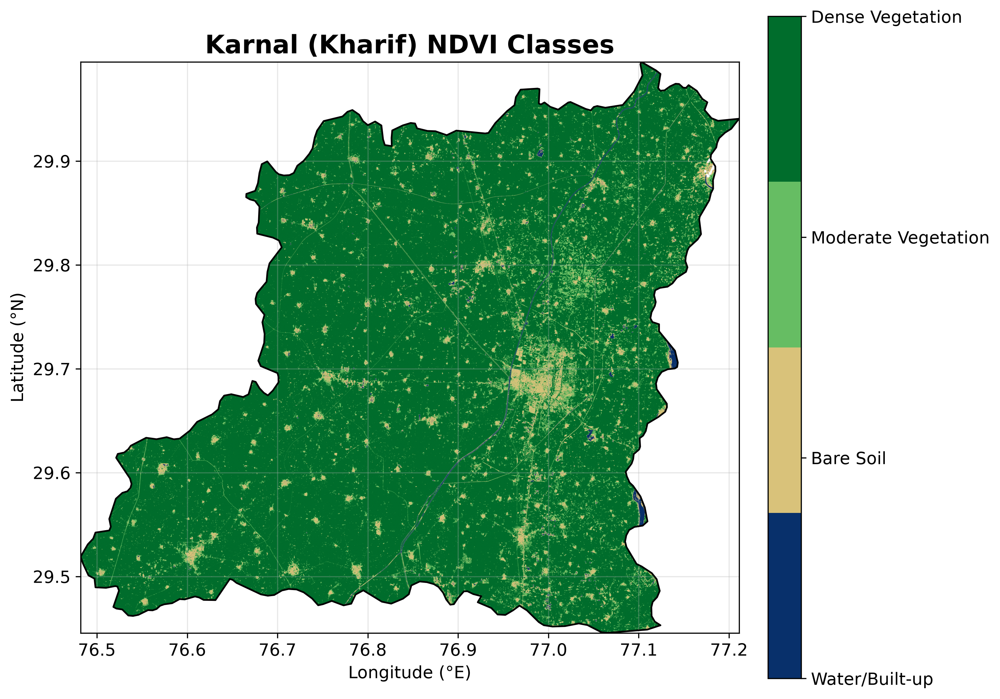

In [32]:
# ==========================================================
# CELL 23 : NDVI CLASSIFICATION MAP
# ==========================================================

from matplotlib.colors import ListedColormap

colors = [

"#08306B",

"#D9C27A",

"#66BD63",

"#006D2C"

]

labels = [

"Water/Built-up",

"Bare Soil",

"Moderate Vegetation",

"Dense Vegetation"

]

cmap = ListedColormap(colors)

fig, ax = plt.subplots(figsize=(10,10))

img = ax.imshow(

ndvi_class,

cmap=cmap,

vmin=0,

vmax=3,

extent=(

src.bounds.left,

src.bounds.right,

src.bounds.bottom,

src.bounds.top

)

)

aoi.boundary.plot(

ax=ax,

color="black",

linewidth=1.2

)

cbar = plt.colorbar(

img,

ticks=[0,1,2,3],

fraction=0.046,

pad=0.04

)

cbar.ax.set_yticklabels(labels)

ax.set_title(

f"{DISTRICT} ({SEASON}) NDVI Classes",

fontsize=18,

fontweight="bold"

)

ax.set_xlabel("Longitude (°E)")

ax.set_ylabel("Latitude (°N)")

ax.grid(alpha=0.3)

plt.tight_layout()

save_figure("NDVI_Classes")

plt.show()

In [33]:
# ==========================================================
# CELL 24 : NDVI AREA STATISTICS
# ==========================================================

pixel_area = 10 * 10

stats = []

for cls in range(4):

    pixels = np.sum(ndvi_class == cls)

    area_m2 = pixels * pixel_area

    area_ha = area_m2 / 10000

    area_sqkm = area_m2 / 1e6

    percentage = (pixels / np.sum(~np.isnan(ndvi_class))) * 100

    stats.append({

        "Class": labels[cls],

        "Pixels": pixels,

        "Area (ha)": area_ha,

        "Area (sq.km)": area_sqkm,

        "Percentage": percentage

    })

area_stats = pd.DataFrame(stats)

display(area_stats.round(2))

save_csv(

area_stats,

"NDVI_Area_Statistics"

)

,Class,Pixels,Area (ha),Area (sq.km),Percentage
0,Water/Built-up,189407,1894.07,18.94,0.63
1,Bare Soil,1226868,12268.68,122.69,4.11
2,Moderate Vegetation,2357192,23571.92,235.72,7.90
3,Dense Vegetation,26075203,260752.03,2607.52,87.36


✓ CSV saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/tables/NDVI_Area_Statistics.csv


✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/figures/NDVI_Area_Chart.png


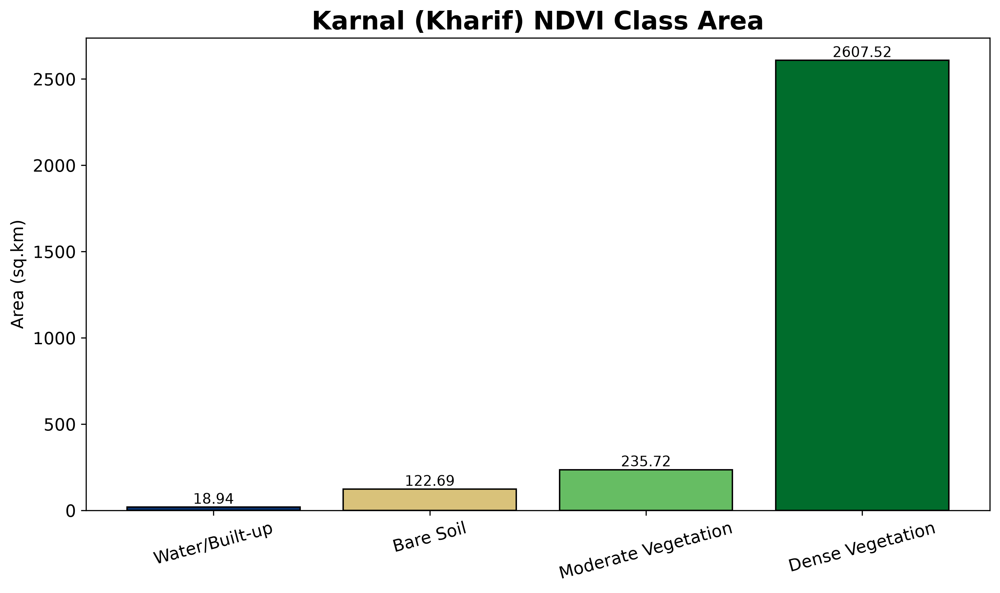

In [34]:
# ==========================================================
# CELL 25 : AREA STATISTICS BAR CHART
# ==========================================================

fig, ax = plt.subplots(figsize=(10,6))

bars = ax.bar(

area_stats["Class"],

area_stats["Area (sq.km)"],

color=colors,

edgecolor="black"

)

for bar in bars:

    h = bar.get_height()

    ax.text(

        bar.get_x()+bar.get_width()/2,

        h,

        f"{h:.2f}",

        ha="center",

        va="bottom",

        fontsize=10

    )

ax.set_title(

f"{DISTRICT} ({SEASON}) NDVI Class Area",

fontsize=18,

fontweight="bold"

)

ax.set_ylabel("Area (sq.km)")

plt.xticks(rotation=15)

plt.tight_layout()

save_figure("NDVI_Area_Chart")

plt.show()

In [35]:
# ==========================================================
# CELL 26 : EXPORT NDVI CLASS RASTER
# ==========================================================

meta = src.meta.copy()

meta.update(

driver="GTiff",

height=ndvi_class.shape[0],

width=ndvi_class.shape[1],

count=1,

dtype="uint8",

transform=clipped_transform

)

save_raster(

ndvi_class.astype(np.uint8),

meta,

f"{DISTRICT}_{SEASON}_NDVI_Class"

)

✓ Raster saved → /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/rasters/Karnal_Kharif_NDVI_Class.tif


In [36]:
# ==========================================================
# CELL 27 : NDWI CALCULATION & EXPORT
# ==========================================================

import numpy as np
import pandas as pd

# ----------------------------------------------------------
# NDWI Formula
# McFeeters (1996)
# NDWI = (Green - NIR) / (Green + NIR)
# ----------------------------------------------------------

np.seterr(divide="ignore", invalid="ignore")

ndwi = (green_clip - nir_clip) / (green_clip + nir_clip)

ndwi = np.where(np.isfinite(ndwi), ndwi, np.nan)

print("="*60)
print("NDWI CALCULATED SUCCESSFULLY")
print("="*60)

print(f"Minimum NDWI : {np.nanmin(ndwi):.4f}")
print(f"Maximum NDWI : {np.nanmax(ndwi):.4f}")
print(f"Mean NDWI    : {np.nanmean(ndwi):.4f}")
print(f"Median NDWI  : {np.nanmedian(ndwi):.4f}")
print(f"Std Dev      : {np.nanstd(ndwi):.4f}")

# ==========================================================
# SAVE NDWI RASTER
# ==========================================================

ndwi_meta = src.meta.copy()

ndwi_meta.update({

    "driver": "GTiff",
    "height": ndwi.shape[0],
    "width": ndwi.shape[1],
    "count": 1,
    "dtype": "float32",
    "transform": clipped_transform

})

save_raster(

    ndwi.astype(np.float32),

    ndwi_meta,

    f"{DISTRICT}_{SEASON}_NDWI"

)

# ==========================================================
# NDWI STATISTICS
# ==========================================================

valid = ndwi[np.isfinite(ndwi)]

ndwi_stats = pd.DataFrame({

    "Statistic":[
        "Minimum",
        "Maximum",
        "Mean",
        "Median",
        "Standard Deviation"
    ],

    "Value":[
        np.min(valid),
        np.max(valid),
        np.mean(valid),
        np.median(valid),
        np.std(valid)
    ]

})

display(ndwi_stats.round(4))

save_csv(

    ndwi_stats,

    f"{DISTRICT}_{SEASON}_NDWI_Statistics"

)

print("\n✓ NDWI Raster Saved")
print("✓ NDWI Statistics Saved")

NDWI CALCULATED SUCCESSFULLY
Minimum NDWI : -1.0000
Maximum NDWI : 0.6052
Mean NDWI    : -0.6503
Median NDWI  : -0.6993
Std Dev      : 0.1726
✓ Raster saved → /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/rasters/Karnal_Kharif_NDWI.tif


,Statistic,Value
0,Minimum,-1.0000
1,Maximum,0.6052
2,Mean,-0.6503
3,Median,-0.6993
4,Standard Deviation,0.1726


✓ CSV saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/tables/Karnal_Kharif_NDWI_Statistics.csv

✓ NDWI Raster Saved
✓ NDWI Statistics Saved


✓ NDWI Map Saved


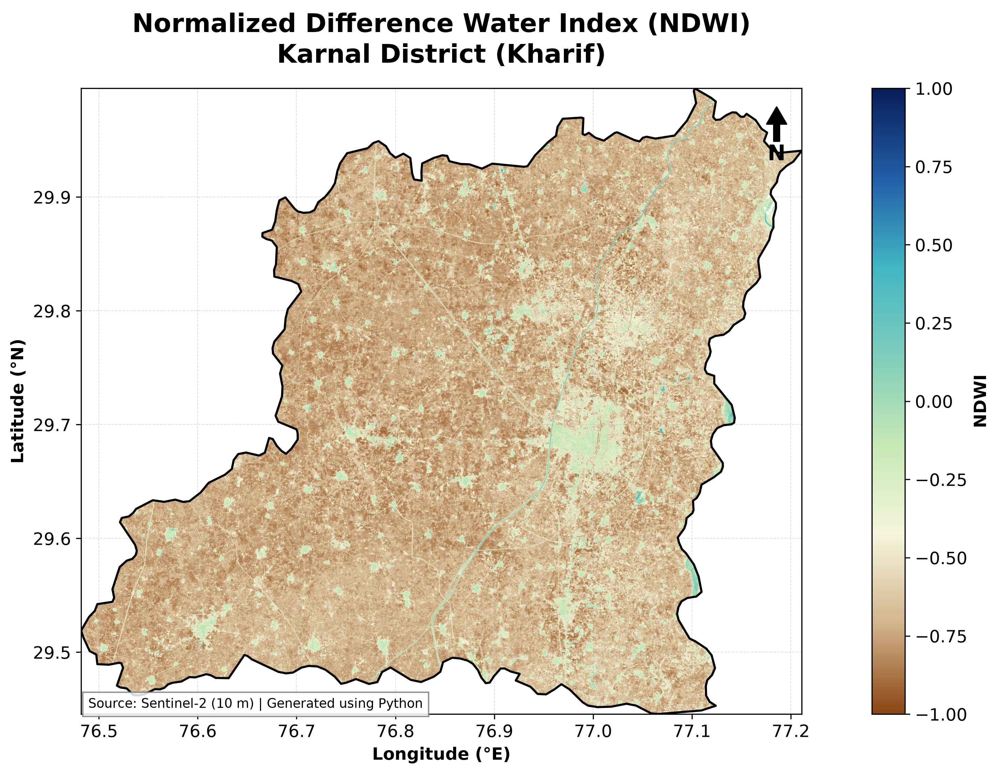

In [37]:
# ==========================================================
# CELL 28 : PUBLICATION QUALITY NDWI MAP
# ==========================================================

from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ----------------------------------------------------------
# Scientific NDWI Color Map
# ----------------------------------------------------------

ndwi_cmap = LinearSegmentedColormap.from_list(

    "NDWI",

    [

        "#8B4513",   # Dry Soil
        "#D2B48C",
        "#F5F5DC",
        "#C7E9B4",
        "#7FCDBB",
        "#41B6C4",
        "#225EA8",
        "#081D58"    # Water

    ]

)

# ==========================================================
# CREATE FIGURE
# ==========================================================

fig, ax = plt.subplots(figsize=(10,10))

# ==========================================================
# DISPLAY NDWI
# ==========================================================

img = ax.imshow(

    ndwi,

    cmap=ndwi_cmap,

    vmin=-1,

    vmax=1,

    extent=(

        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top

    )

)

# ==========================================================
# AOI BOUNDARY
# ==========================================================

aoi.boundary.plot(

    ax=ax,

    color="black",

    linewidth=1.5

)

# ==========================================================
# GRID
# ==========================================================

ax.grid(

    linestyle="--",

    linewidth=0.5,

    alpha=0.4

)

# ==========================================================
# AXIS LABELS
# ==========================================================

ax.set_xlabel(

    "Longitude (°E)",

    fontsize=12,

    fontweight="bold"

)

ax.set_ylabel(

    "Latitude (°N)",

    fontsize=12,

    fontweight="bold"

)

# ==========================================================
# TITLE
# ==========================================================

ax.set_title(

    f"Normalized Difference Water Index (NDWI)\n"
    f"{DISTRICT} District ({SEASON})",

    fontsize=18,

    fontweight="bold",

    pad=18

)

# ==========================================================
# NORTH ARROW
# ==========================================================

ax.annotate(

    "N",

    xy=(0.965,0.97),

    xytext=(0.965,0.885),

    arrowprops=dict(

        facecolor="black",

        width=4,

        headwidth=14

    ),

    fontsize=15,

    fontweight="bold",

    ha="center",

    xycoords=ax.transAxes

)

# ==========================================================
# COLORBAR
# ==========================================================

divider = make_axes_locatable(ax)

cax = divider.append_axes(

    "right",

    size="4%",

    pad=0.15

)

cb = plt.colorbar(

    img,

    cax=cax

)

cb.set_label(

    "NDWI",

    fontsize=12,

    fontweight="bold"

)

# ==========================================================
# FOOTER
# ==========================================================

ax.text(

    0.01,

    0.01,

    "Source: Sentinel-2 (10 m) | Generated using Python",

    fontsize=9,

    transform=ax.transAxes,

    bbox=dict(

        facecolor="white",

        edgecolor="gray",

        alpha=0.85

    )

)

fig.tight_layout()

# ==========================================================
# SAVE FIGURE
# ==========================================================

fig.savefig(

    FIGURE_DIR / f"{DISTRICT}-{SEASON}_NDWI_Map.png",

    dpi=600,

    bbox_inches="tight",

    facecolor="white"

)

print("✓ NDWI Map Saved")

plt.show()

plt.close(fig)

In [38]:
# ==========================================================
# CELL 29 : SOIL ADJUSTED VEGETATION INDEX (SAVI)
# ==========================================================

L = 0.5

savi = ((nir_clip - red_clip) / (nir_clip + red_clip + L)) * (1 + L)

savi = np.where(
    np.isfinite(savi),
    savi,
    np.nan
)

print("="*60)
print("SAVI Successfully Calculated")
print("="*60)

print("Minimum :", np.nanmin(savi))
print("Maximum :", np.nanmax(savi))
print("Mean    :", np.nanmean(savi))

# ==========================================================
# SAVE SAVI RASTER
# ==========================================================

savi_meta = src.meta.copy()

savi_meta.update({

    "driver":"GTiff",

    "height":savi.shape[0],

    "width":savi.shape[1],

    "count":1,

    "dtype":"float32",

    "transform":clipped_transform

})

save_raster(

    savi.astype(np.float32),

    savi_meta,

    f"{DISTRICT}_{SEASON}_SAVI"

)

# ==========================================================
# SAVE STATISTICS
# ==========================================================

savi_stats = pd.DataFrame({

    "Statistic":[
        "Minimum",
        "Maximum",
        "Mean",
        "Median",
        "Std Dev"
    ],

    "Value":[

        np.nanmin(savi),

        np.nanmax(savi),

        np.nanmean(savi),

        np.nanmedian(savi),

        np.nanstd(savi)

    ]

})

display(savi_stats)

save_csv(

    savi_stats,

    f"{DISTRICT}_{SEASON}_SAVI_Statistics"

)

SAVI Successfully Calculated
Minimum : -0.75196195
Maximum : 1.4998201
Mean    : 0.64715666
✓ Raster saved → /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/rasters/Karnal_Kharif_SAVI.tif


,Statistic,Value
0,Minimum,-0.751962
1,Maximum,1.499820
2,Mean,0.647157
3,Median,0.889248
4,Std Dev,0.577213


✓ CSV saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/tables/Karnal_Kharif_SAVI_Statistics.csv


In [39]:
print("ndbi" in globals())

False


✓ SAVI Map Saved


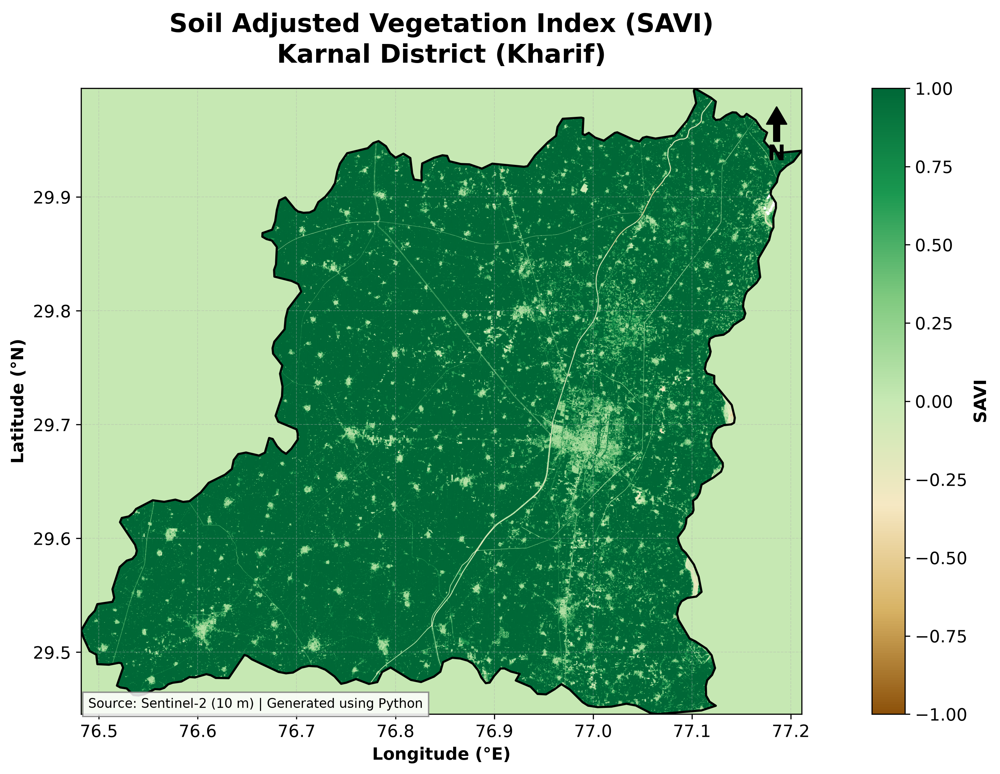

In [40]:
# ==========================================================
# CELL 30 : PUBLICATION QUALITY SAVI MAP
# ==========================================================

from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ----------------------------------------------------------
# Scientific SAVI Colormap
# ----------------------------------------------------------

savi_cmap = LinearSegmentedColormap.from_list(

    "SAVI",

    [

        "#8c510a",   # Bare Soil
        "#d8b365",
        "#f6e8c3",
        "#c7e9b4",
        "#7fc97f",
        "#1a9850",
        "#006837"    # Dense Vegetation

    ]

)

# ==========================================================
# CREATE FIGURE
# ==========================================================

fig, ax = plt.subplots(figsize=(10,10))

# ==========================================================
# DISPLAY SAVI
# ==========================================================

img = ax.imshow(

    savi,

    cmap=savi_cmap,

    vmin=-1,

    vmax=1,

    extent=(

        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top

    )

)

# ==========================================================
# AOI BOUNDARY
# ==========================================================

aoi.boundary.plot(

    ax=ax,

    color="black",

    linewidth=1.5

)

# ==========================================================
# GRID
# ==========================================================

ax.grid(

    linestyle="--",

    linewidth=0.5,

    alpha=0.4

)

# ==========================================================
# AXIS LABELS
# ==========================================================

ax.set_xlabel(

    "Longitude (°E)",

    fontsize=12,

    fontweight="bold"

)

ax.set_ylabel(

    "Latitude (°N)",

    fontsize=12,

    fontweight="bold"

)

# ==========================================================
# TITLE
# ==========================================================

ax.set_title(

    f"Soil Adjusted Vegetation Index (SAVI)\n"
    f"{DISTRICT} District ({SEASON})",

    fontsize=18,

    fontweight="bold",

    pad=18

)

# ==========================================================
# NORTH ARROW
# ==========================================================

ax.annotate(

    "N",

    xy=(0.965,0.97),

    xytext=(0.965,0.885),

    arrowprops=dict(

        facecolor="black",

        width=4,

        headwidth=14

    ),

    fontsize=15,

    fontweight="bold",

    ha="center",

    xycoords=ax.transAxes

)

# ==========================================================
# COLORBAR
# ==========================================================

divider = make_axes_locatable(ax)

cax = divider.append_axes(

    "right",

    size="4%",

    pad=0.15

)

cb = plt.colorbar(

    img,

    cax=cax

)

cb.set_label(

    "SAVI",

    fontsize=12,

    fontweight="bold"

)

# ==========================================================
# FOOTER
# ==========================================================

ax.text(

    0.01,

    0.01,

    "Source: Sentinel-2 (10 m) | Generated using Python",

    fontsize=9,

    transform=ax.transAxes,

    bbox=dict(

        facecolor="white",

        edgecolor="gray",

        alpha=0.85

    )

)

fig.tight_layout()

# ==========================================================
# SAVE FIGURE
# ==========================================================

fig.savefig(

    FIGURE_DIR / f"{DISTRICT}-{SEASON}_SAVI_Map.png",

    dpi=600,

    bbox_inches="tight",

    facecolor="white"

)

print("✓ SAVI Map Saved")

plt.show()

plt.close(fig)

In [41]:
print("blue_clip" in globals())
print("green_clip" in globals())
print("red_clip" in globals())
print("nir_clip" in globals())
print("swir1_clip" in globals())
print("swir2_clip" in globals())

True
True
True
True
False
False


In [42]:
# ==========================================================
# EXTRACT ALL SENTINEL-2 BANDS
# ==========================================================

# clipped_image shape = (bands, rows, cols)

blue_clip  = clipped_image[0].astype(np.float32)
green_clip = clipped_image[1].astype(np.float32)
red_clip   = clipped_image[2].astype(np.float32)
nir_clip   = clipped_image[3].astype(np.float32)
swir1_clip = clipped_image[4].astype(np.float32)
swir2_clip = clipped_image[5].astype(np.float32)

print("="*60)
print("Sentinel-2 Bands Extracted")
print("="*60)

print(f"Blue   (B2) : {blue_clip.shape}")
print(f"Green  (B3) : {green_clip.shape}")
print(f"Red    (B4) : {red_clip.shape}")
print(f"NIR    (B8) : {nir_clip.shape}")
print(f"SWIR1 (B11) : {swir1_clip.shape}")
print(f"SWIR2 (B12) : {swir2_clip.shape}")

Sentinel-2 Bands Extracted
Blue   (B2) : (6122, 8118)
Green  (B3) : (6122, 8118)
Red    (B4) : (6122, 8118)
NIR    (B8) : (6122, 8118)
SWIR1 (B11) : (6122, 8118)
SWIR2 (B12) : (6122, 8118)


In [43]:
print("swir1_clip" in globals())
print("swir2_clip" in globals())

True
True


In [44]:
# ==========================================================
# CELL 31 : NDBI CALCULATION
# ==========================================================

# NDBI = (SWIR - NIR) / (SWIR + NIR)

np.seterr(divide="ignore", invalid="ignore")

ndbi = (swir1_clip - nir_clip) / (swir1_clip + nir_clip)

ndbi = np.where(np.isfinite(ndbi), ndbi, np.nan)

print("="*60)
print("NDBI Successfully Calculated")
print("="*60)

print("Minimum :", np.nanmin(ndbi))
print("Maximum :", np.nanmax(ndbi))
print("Mean    :", np.nanmean(ndbi))

# ==========================================================
# SAVE NDBI RASTER
# ==========================================================

ndbi_meta = src.meta.copy()

ndbi_meta.update({

    "driver":"GTiff",

    "height":ndbi.shape[0],

    "width":ndbi.shape[1],

    "count":1,

    "dtype":"float32",

    "transform":clipped_transform

})

save_raster(

    ndbi.astype(np.float32),

    ndbi_meta,

    f"{DISTRICT}_{SEASON}_NDBI"

)

# ==========================================================
# NDBI STATISTICS
# ==========================================================

ndbi_stats = pd.DataFrame({

    "Statistic":[

        "Minimum",

        "Maximum",

        "Mean",

        "Median",

        "Std Dev"

    ],

    "Value":[

        np.nanmin(ndbi),

        np.nanmax(ndbi),

        np.nanmean(ndbi),

        np.nanmedian(ndbi),

        np.nanstd(ndbi)

    ]

})

display(ndbi_stats)

save_csv(

    ndbi_stats,

    "NDBI_Statistics"

)

NDBI Successfully Calculated
Minimum : -0.7298487
Maximum : 0.7199434
Mean    : -0.3040741
✓ Raster saved → /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/rasters/Karnal_Kharif_NDBI.tif


,Statistic,Value
0,Minimum,-0.729849
1,Maximum,0.719943
2,Mean,-0.304074
3,Median,-0.346098
4,Std Dev,0.131099


✓ CSV saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/tables/NDBI_Statistics.csv


✓ NDBI Map Saved


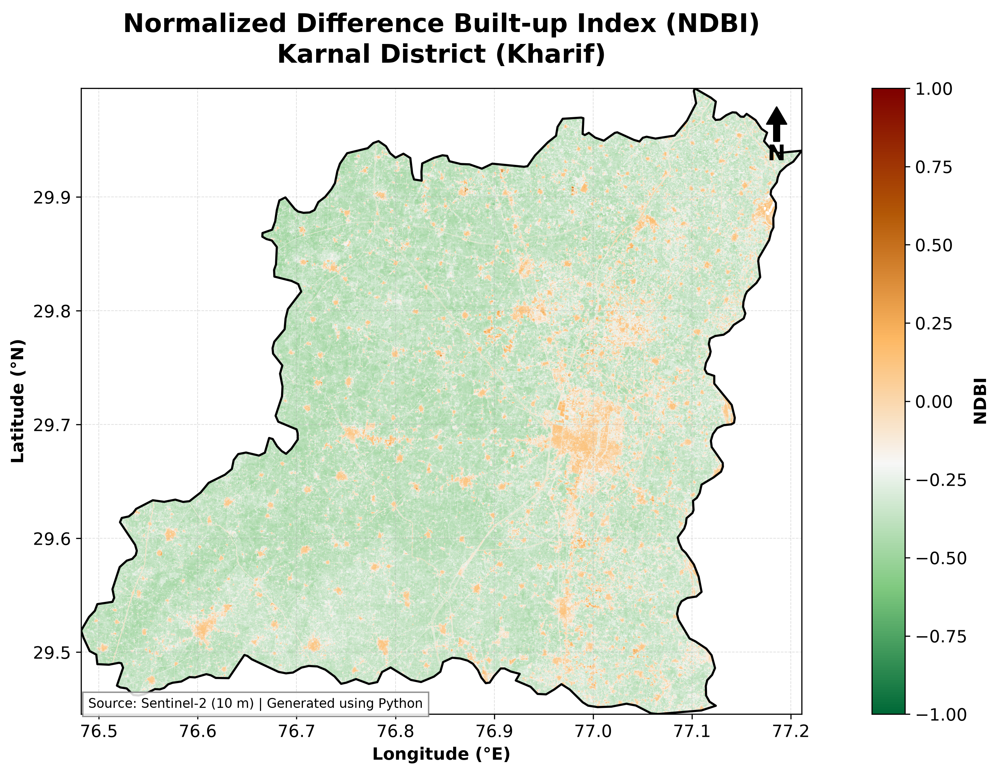

In [45]:
# ==========================================================
# CELL 32 : PUBLICATION QUALITY NDBI MAP
# ==========================================================

from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ----------------------------------------------------------
# Scientific NDBI Colormap
# ----------------------------------------------------------

ndbi_cmap = LinearSegmentedColormap.from_list(

    "NDBI",

    [

        "#006837",   # Dense vegetation
        "#7FC97F",
        "#F7F7F7",
        "#FDB863",
        "#B35806",
        "#7F0000"    # Dense built-up

    ]

)

# ==========================================================
# CREATE FIGURE
# ==========================================================

fig, ax = plt.subplots(figsize=(10,10))

# ==========================================================
# DISPLAY NDBI
# ==========================================================

img = ax.imshow(

    ndbi,

    cmap=ndbi_cmap,

    vmin=-1,

    vmax=1,

    extent=(

        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top

    )

)

# ==========================================================
# AOI Boundary
# ==========================================================

aoi.boundary.plot(

    ax=ax,

    color="black",

    linewidth=1.5

)

# ==========================================================
# Grid
# ==========================================================

ax.grid(

    linestyle="--",

    linewidth=0.5,

    alpha=0.4

)

# ==========================================================
# Axis Labels
# ==========================================================

ax.set_xlabel(

    "Longitude (°E)",

    fontsize=12,

    fontweight="bold"

)

ax.set_ylabel(

    "Latitude (°N)",

    fontsize=12,

    fontweight="bold"

)

# ==========================================================
# Title
# ==========================================================

ax.set_title(

    f"Normalized Difference Built-up Index (NDBI)\n"
    f"{DISTRICT} District ({SEASON})",

    fontsize=18,

    fontweight="bold",

    pad=18

)

# ==========================================================
# North Arrow
# ==========================================================

ax.annotate(

    "N",

    xy=(0.965,0.97),

    xytext=(0.965,0.885),

    arrowprops=dict(

        facecolor="black",

        width=4,

        headwidth=14

    ),

    fontsize=15,

    fontweight="bold",

    ha="center",

    xycoords=ax.transAxes

)

# ==========================================================
# Colorbar
# ==========================================================

divider = make_axes_locatable(ax)

cax = divider.append_axes(

    "right",

    size="4%",

    pad=0.15

)

cb = plt.colorbar(

    img,

    cax=cax

)

cb.set_label(

    "NDBI",

    fontsize=12,

    fontweight="bold"

)

# ==========================================================
# Footer
# ==========================================================

ax.text(

    0.01,

    0.01,

    "Source: Sentinel-2 (10 m) | Generated using Python",

    fontsize=9,

    transform=ax.transAxes,

    bbox=dict(

        facecolor="white",

        edgecolor="gray",

        alpha=0.85

    )

)

fig.tight_layout()

# ==========================================================
# SAVE FIGURE
# ==========================================================

fig.savefig(

    FIGURE_DIR / f"{DISTRICT}-{SEASON}_NDBI_Map.png",

    dpi=600,

    bbox_inches="tight",

    facecolor="white"

)

print("✓ NDBI Map Saved")

plt.show()

plt.close(fig)

In [46]:
# ==========================================================
# FINAL CELL : VERIFY OUTPUTS FOR NOTEBOOK 2
# ==========================================================

from pathlib import Path

print("=" * 70)
print("VERIFYING EXPORTED FILES")
print("=" * 70)

folders = {

    "Figures": FIGURE_DIR,

    "Tables": TABLE_DIR,

    "Rasters": RASTER_DIR

}

for folder_name, folder in folders.items():

    print(f"\n{folder_name}")

    files = sorted(Path(folder).glob("*"))

    for f in files:

        print("✓", f.name)

print("\n" + "=" * 70)
print("Notebook 1 Completed Successfully")
print("Ready for Machine Learning Notebook")
print("=" * 70)

VERIFYING EXPORTED FILES

Figures
✓ District_Boundary.png
✓ Karnal(Kharif) False Color Composite.png
✓ Karnal-(Kharif) (False COLOR COMPOSITE).png
✓ Karnal-Kharif (False COLOR COMPOSITE).png
✓ Karnal-Kharif (Histogram of Sentinal-2 Spectral Bands).png
✓ Karnal-Kharif (Spectral Distribution of Sentinal-2 Bands).png
✓ Karnal-Kharif (TRUE COLOR COMPOSITE).png
✓ Karnal-Kharif (Verify Raster).png
✓ Karnal-Kharif (true COLOR COMPOSITE rgb cliped).png
✓ Karnal-Kharif NDVI Map.png
✓ Karnal-Kharif_Correlation_Matrix.png
✓ Karnal-Kharif_NDBI_Map.png
✓ Karnal-Kharif_NDWI_Map.png
✓ Karnal-Kharif_SAVI_Map.png
✓ Karnal-Kharif_Spectral_Indices_Comparison.png
✓ NDVI_Area_Chart.png
✓ NDVI_Classes.png
✓ NDVI_Histogram.png

Tables
✓ Band_Statistics.csv
✓ Karnal_Kharif_Correlation_Matrix.csv
✓ Karnal_Kharif_Feature_List.csv
✓ Karnal_Kharif_NDVI_Statistics.csv
✓ Karnal_Kharif_NDWI_Statistics.csv
✓ Karnal_Kharif_SAVI_Statistics.csv
✓ NDBI_Statistics.csv
✓ NDVI_Area_Statistics.csv
✓ Raster_Metadata.csv

Rast

In [ ]:
# ==========================================================
# CELL 34 : FEATURE STACK FOR MACHINE LEARNING
# ==========================================================

# Feature Stack
#
# Bands
# B2  Blue
# B3  Green
# B4  Red
# B8  NIR
# B11 SWIR1
# B12 SWIR2
#
# Spectral Indices
# NDVI
# NDWI
# SAVI
# NDBI
# ==========================================================

feature_stack = np.stack([

    blue_clip,

    green_clip,

    red_clip,

    nir_clip,

    swir1_clip,

    swir2_clip,

    ndvi,

    ndwi,

    savi,

    ndbi

], axis=0)

print("="*60)
print("Feature Stack Created Successfully")
print("="*60)

print("Feature Stack Shape :", feature_stack.shape)

print()

print("Number of Features :", feature_stack.shape[0])

print("Rows :", feature_stack.shape[1])

print("Columns :", feature_stack.shape[2])

# ==========================================================
# FEATURE NAMES
# ==========================================================

feature_names = [

    "Blue (B2)",

    "Green (B3)",

    "Red (B4)",

    "NIR (B8)",

    "SWIR1 (B11)",

    "SWIR2 (B12)",

    "NDVI",

    "NDWI",

    "SAVI",

    "NDBI"

]

feature_df = pd.DataFrame({

    "Feature No": np.arange(1,11),

    "Feature": feature_names

})

display(feature_df)

# ==========================================================
# SAVE FEATURE LIST
# ==========================================================

save_csv(

    feature_df,

    f"{DISTRICT}_{SEASON}_Feature_List"

)

# ==========================================================
# SAVE FEATURE STACK
# ==========================================================

feature_meta = src.meta.copy()

feature_meta.update({

    "driver":"GTiff",

    "height":feature_stack.shape[1],

    "width":feature_stack.shape[2],

    "count":feature_stack.shape[0],

    "dtype":"float32",

    "transform":clipped_transform

})

save_raster(

    feature_stack.astype(np.float32),

    feature_meta,

    f"{DISTRICT}_{SEASON}_FeatureStack"

)

print("\n✓ Feature Stack Saved")
print("✓ Feature List Saved")

Feature Stack Created Successfully
Feature Stack Shape : (10, 6122, 8118)

Number of Features : 10
Rows : 6122
Columns : 8118


,Feature No,Feature
0,1,Blue (B2)
1,2,Green (B3)
2,3,Red (B4)
3,4,NIR (B8)
4,5,SWIR1 (B11)
5,6,SWIR2 (B12)
6,7,NDVI
7,8,NDWI
8,9,SAVI
9,10,NDBI


✓ CSV saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/tables/Karnal_Kharif_Feature_List.csv


In [ ]:
# ==========================================================
# CELL 33 : MULTI-INDEX COMPARISON
# ==========================================================

from matplotlib.colors import LinearSegmentedColormap

fig, axes = plt.subplots(

    2,
    2,

    figsize=(18,16)

)

# ----------------------------------------------------------
# Color Maps
# ----------------------------------------------------------

veg_cmap = LinearSegmentedColormap.from_list(

    "Vegetation",

    [

        "#8c510a",
        "#d8b365",
        "#f6e8c3",
        "#c7e9b4",
        "#7fc97f",
        "#1a9850",
        "#006837"

    ]

)

water_cmap = LinearSegmentedColormap.from_list(

    "Water",

    [

        "#8c510a",
        "#f6e8c3",
        "#c7e9b4",
        "#41b6c4",
        "#225ea8",
        "#081d58"

    ]

)

builtup_cmap = LinearSegmentedColormap.from_list(

    "Builtup",

    [

        "#006837",
        "#7fc97f",
        "#f7f7f7",
        "#fdb863",
        "#b35806",
        "#7f0000"

    ]

)

datasets = [

    ("NDVI", ndvi, veg_cmap),

    ("NDWI", ndwi, water_cmap),

    ("SAVI", savi, veg_cmap),

    ("NDBI", ndbi, builtup_cmap)

]

for ax, (title, image, cmap) in zip(

    axes.ravel(),

    datasets

):

    im = ax.imshow(

        image,

        cmap=cmap,

        vmin=-1,

        vmax=1,

        extent=(

            src.bounds.left,
            src.bounds.right,
            src.bounds.bottom,
            src.bounds.top

        )

    )

    aoi.boundary.plot(

        ax=ax,

        color="black",

        linewidth=1

    )

    ax.set_title(

        title,

        fontsize=16,

        fontweight="bold"

    )

    ax.set_xlabel("Longitude (°E)")

    ax.set_ylabel("Latitude (°N)")

    ax.grid(

        linestyle="--",

        linewidth=0.4,

        alpha=0.4

    )

    plt.colorbar(

        im,

        ax=ax,

        fraction=0.045,

        pad=0.03

    )

fig.suptitle(

    f"Spectral Indices Comparison\n{DISTRICT} District ({SEASON})",

    fontsize=22,

    fontweight="bold"

)

fig.tight_layout()

# ==========================================================
# SAVE FIGURE
# ==========================================================

fig.savefig(

    FIGURE_DIR /

    f"{DISTRICT}-{SEASON}_Spectral_Indices_Comparison.png",

    dpi=600,

    bbox_inches="tight",

    facecolor="white"

)

print("✓ Spectral Comparison Saved")

plt.show()

plt.close(fig)

In [4]:
# ==========================================================
# CELL 35 : FEATURE CORRELATION MATRIX
# ==========================================================

import seaborn as sns

# ==========================================================
# Flatten all features
# ==========================================================

feature_data = []

for band in feature_stack:

    values = band.flatten()

    values = values[np.isfinite(values)]

    feature_data.append(values)

# ==========================================================
# Make all arrays equal length
# ==========================================================

min_length = min(len(x) for x in feature_data)

feature_data = [

    x[:min_length]

    for x in feature_data

]

# ==========================================================
# Create DataFrame
# ==========================================================

corr_df = pd.DataFrame(

    np.array(feature_data).T,

    columns=feature_names

)

# ==========================================================
# Correlation Matrix
# ==========================================================

corr_matrix = corr_df.corr()

display(corr_matrix.round(3))

# ==========================================================
# Save Correlation Matrix CSV
# ==========================================================

save_csv(

    corr_matrix.round(5),

    f"{DISTRICT}_{SEASON}_Correlation_Matrix"

)

# ==========================================================
# Publication Heatmap
# ==========================================================

fig, ax = plt.subplots(

    figsize=(11,9)

)

sns.heatmap(

    corr_matrix,

    annot=True,

    fmt=".2f",

    cmap="RdYlGn",

    linewidths=0.5,

    square=True,

    cbar_kws={

        "label":"Pearson Correlation"

    },

    ax=ax

)

ax.set_title(

    f"Feature Correlation Matrix\n"
    f"{DISTRICT} District ({SEASON})",

    fontsize=18,

    fontweight="bold",

    pad=20

)

plt.xticks(

    rotation=45,

    ha="right"

)

plt.yticks(

    rotation=0

)

plt.tight_layout()

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure(

    f"{DISTRICT}-{SEASON}_Correlation_Matrix"

)

plt.show()

plt.close(fig)

print("="*60)
print("Correlation Analysis Completed")
print("="*60)


NameError: name 'feature_stack' is not defined

In [ ]:


# ==========================================================
# CELL 36 : PRINCIPAL COMPONENT ANALYSIS (PCA)
# ==========================================================

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ==========================================================
# Prepare Feature Matrix
# ==========================================================

feature_matrix = feature_stack.reshape(
    feature_stack.shape[0],
    -1
).T

feature_matrix = pd.DataFrame(
    feature_matrix,
    columns=feature_names
)

# ==========================================================
# Remove NaN Pixels
# ==========================================================

feature_matrix = feature_matrix.dropna()

print("="*60)
print("Feature Matrix Shape")
print("="*60)
print(feature_matrix.shape)

# ==========================================================
# Standardization
# ==========================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(feature_matrix)

# ==========================================================
# PCA
# ==========================================================

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_

print("="*60)
print("Explained Variance")
print("="*60)

for i, var in enumerate(explained_variance):

    print(f"PC{i+1}: {var*100:.2f}%")

# ==========================================================
# Save Explained Variance
# ==========================================================

pca_df = pd.DataFrame({

    "Principal Component":[

        f"PC{i+1}"

        for i in range(len(explained_variance))

    ],

    "Explained Variance (%)":

    explained_variance*100,

    "Cumulative Variance (%)":

    np.cumsum(explained_variance)*100

})

display(pca_df.round(2))

save_csv(

    pca_df,

    f"{DISTRICT}_{SEASON}_PCA_Statistics"

)

# ==========================================================
# Scree Plot
# ==========================================================

fig, ax = plt.subplots(figsize=(10,6))

ax.plot(

    range(1, len(explained_variance)+1),

    explained_variance*100,

    marker="o",

    linewidth=2,

    markersize=8

)

ax.set_xlabel(

    "Principal Component",

    fontsize=12,

    fontweight="bold"

)

ax.set_ylabel(

    "Explained Variance (%)",

    fontsize=12,

    fontweight="bold"

)

ax.set_title(

    f"PCA Scree Plot\n{DISTRICT} District ({SEASON})",

    fontsize=18,

    fontweight="bold"

)

ax.grid(

    alpha=0.3

)

fig.tight_layout()

fig.savefig(

    FIGURE_DIR /

    f"{DISTRICT}-{SEASON}_PCA_ScreePlot.png",

    dpi=600,

    bbox_inches="tight",

    facecolor="white"

)

print("✓ PCA Scree Plot Saved")

plt.show()

plt.close(fig)

# ==========================================================
# PCA Loading Matrix
# ==========================================================

loading_matrix = pd.DataFrame(

    pca.components_.T,

    columns=[

        f"PC{i+1}"

        for i in range(len(feature_names))

    ],

    index=feature_names

)

display(loading_matrix.round(3))

save_csv(

    loading_matrix,

    f"{DISTRICT}_{SEASON}_PCA_Loadings"

)

print("="*60)
print("PCA Completed Successfully")
print("="*60)
